# Create Boundary Conditions for +4K climate


Plan:

Problem is that we dont't have restart files for future climates. I would like to use the same intial conditions but starting 1st December to give the model until 15th January to spin up. This should be possible. We can use december and january sst and sea ice. We will use 4xCO2 experiments for a strong global warming signal. Theses simulations are started from preindustrial state (1850) and then run for 170 years. This exsits for the MPI-ESM-HR which as failry high resolution and therefore hopefully realistic sst and sea ice pattern. We use the final years for a converged warm climate state.

Important:
 - We were not able to make ICON work with the SST from the MPI-ESM-HR simulation! Instead we use a simple +4K uniform warming (see `src/create_uniform4k_sst.sh`).
 - Sea Ice concentrations from 4xCO2 simulation in MPI-ESM-HR created with this notebook and work with ICON.
 - Greenhouse Gas concentrations are also taken from this simulation and their time coordinate adapted


ICON Run script adaptations:

- start Dec 1st: adapt intialisation files' time coordiante
- link new boundary conditions (lines 539-540 in exp.iconml_amip_2mom_reference_60s.run)
- adpat greenhouse gases to 4xCO2 (line 570)

Useful information for work on levante

- intial and boundary conditions for historical times: /pool/data/ICON/grids/public/mpim/0054/
- script for generating `/pool/data/ICON/grids/public/mpim/0054/09-remap-sst-and-seaice-2020.sh` : this uses standard cdo remapping for generating the boundary conditions
- they use this data: `/pool/data/ICON/grids/private/mpim/icon_preprocessing/source/sst_and_seaice/1.1.8` to interpolate to ICON grid




# Boundary Conditions

We look for SST, Sea Ice in the data catalogue. SST is in `Omon`, Sea Ice is in `SImon`

In [1]:
import xarray as xr
import intake_esm
import intake
import numpy as np
import pandas as pd

In [2]:
%%time
cat = intake.open_esm_datastore("/pool/data/Catalogs/dkrz_cmip6_disk.json")

/work/ka1176/paul/conda/ML_trop_temp/lib/python3.11/site-packages/intake_esm/cat.py:249: DtypeWarning: Columns (21,22,23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


CPU times: user 44.4 s, sys: 2.88 s, total: 47.3 s
Wall time: 47.9 s


In [19]:
!ls /work/ik1017/CMIP6/data/CMIP6/CMIP/MPI-M/MPI-ESM1-2-HR/

1pctCO2  abrupt-4xCO2  amip  historical  piControl


## Adapt times method

In [ ]:
def adapt_times(ds, old_months = slice('2013-11', '2014-03'), year_offset=6) :
    """
    Select a time range from a dataset and shift the times forward by a specified number of years.
    
    This function extracts data for a specific time period and updates both the time coordinate
    and time_bnds variable by adding a year offset, effectively creating a copy of the data
    with shifted temporal coordinates.
    
    Parameters
    ----------
    ds : xarray.Dataset
        Input dataset containing 'time' coordinate and 'time_bnds' variable.
    old_months : slice, optional
        Time slice to select from the dataset. Default is slice('2013-12', '2014-02').
    month_offset : int, optional
        Number of years to add to the selected time coordinates. Default is 6.
    
    """
    times = ds.time.sel(time = old_months)
    times_updated = [ np.datetime64(pd.Timestamp(t) + pd.DateOffset(years=year_offset)) for t in times.values ]
    time_bnds_updated = [ [ np.datetime64(pd.Timestamp(t[0]) + pd.DateOffset(years=year_offset)),np.datetime64(pd.Timestamp(t[1]) + pd.DateOffset(years=year_offset))]  for t in ds.sel(time=times).time_bnds.values ]
    ds_out = ds.sel(time=times)
    ds_out["time"] = times_updated
    ds_out["time_bnds"] = (["time", "bnds"], time_bnds_updated)
    return ds_out

## Get data

### Sea Ice

In [27]:
cat_SI = cat.search(
    experiment_id=["abrupt-4xCO2"],
    table_id="SImon",
    grid_label="gn",
    institution_id="MPI-M",
    source_id="MPI-ESM1-2-HR",
    time_min=201001,
    variable_id = "siconca"
)

In [28]:
cat_SI.df

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,dcpp_init_year,version,...,frequency,time_reduction,long_name,units,realm,level_type,time_min,time_max,format,uri
0,CMIP,MPI-M,MPI-ESM1-2-HR,abrupt-4xCO2,r1i1p1f1,SImon,siconca,gn,NaN,v20190710,...,mon,mean,Sea-Ice Area Percentage (Atmospheric Grid),%,seaIce,NaN,201001.0,201412,netcdf,/work/ik1017/CMIP6/data/CMIP6/CMIP/MPI-M/MPI-E...


In [ ]:
SI_path = cat_SI.df.uri
sea_ice = xr.open_dataset(SI_path[0], engine="h5netcdf")

'/work/ik1017/CMIP6/data/CMIP6/CMIP/MPI-M/MPI-ESM1-2-HR/abrupt-4xCO2/r1i1p1f1/SImon/siconca/gn/v20190710/siconca_SImon_MPI-ESM1-2-HR_abrupt-4xCO2_r1i1p1f1_gn_201001-201412.nc'

/tmp/ipykernel_1828949/396741459.py:23: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds_out["time"] = times_updated
/tmp/ipykernel_1828949/396741459.py:23: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond prec

<xarray.Dataset>
Dimensions:    (time: 5, bnds: 2, lat: 192, lon: 384)
Coordinates:
  * time       (time) datetime64[ns] 2019-11-16 ... 2020-03-16T12:00:00
  * lat        (lat) float64 -89.28 -88.36 -87.42 -86.49 ... 87.42 88.36 89.28
  * lon        (lon) float64 0.0 0.9375 1.875 2.812 ... 356.2 357.2 358.1 359.1
    type       |S7 ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 2019-11-01 2019-12-01 ... 2020-04-01
    lat_bnds   (lat, bnds) float64 ...
    lon_bnds   (lon, bnds) float64 ...
    siconca    (time, lat, lon) float32 0.0 0.0 0.0 0.0 ... 96.25 96.26 96.27
Attributes: (12/47)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    contact:                cmip6-mpi-esm@dkrz.de
    ...                     ...
    title:                  MPI-ESM1-2-HR output prepared for CMIP6
    variable_id:         

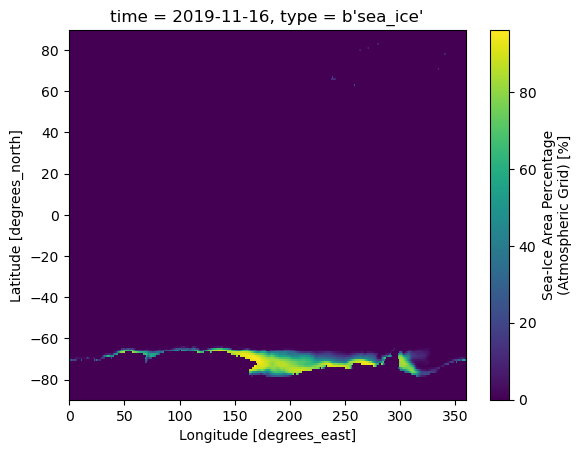

In [ ]:
sea_ice_out = adapt_times(sea_ice)
print(sea_ice_out)
sea_ice_out = sea_ice_out.rename({"siconca" : "siconcbcs"})
sea_ice_out.isel(time=0)["siconcbcs"].plot(x="lon", y="lat")
sea_ice_out.drop("type").to_netcdf("../data/sea_ice_bc_4xCO2.nc", engine="h5netcdf")

## CO2: Take preindustrial value (1850) and multiply by 4

In [35]:
ds = xr.open_dataset("/pool/data/ICON/grids/public/mpim/common/greenhouse_gases/greenhouse_1pctCO2.nc")
ds_pre = ds.sel(time=[1850.,1851.])
ds_pre["time"] = [2019.,2020.]
ds_pre["time"].attrs = ds["time"].attrs
ds_4xCO2 = ds_pre
ds_4xCO2["CO2"] = ds_4xCO2["CO2"] *4

In [ ]:
ds_4xCO2.to_netcdf("../data/greenhouse_gases_4xCO2.nc")